# Grocery Promotion Post-Event Analysis & Price Audit

**Business questions (center-store pricing & promo team)**
1. When an item goes into the weekly mailer, how many *incremental* units does it really sell?
2. How much of that lift is pulled forward from next week or taken from sister items (cannibalization)?
3. How price-sensitive is each category (elasticity), and which promos are worth repeating?
4. Is the shelf-price architecture healthy (private-label gap, price endings)?

**Data:** dunnhumby *The Complete Journey* (2017 release via the `completejourney_py` package):
1.47M grocery transactions from 801 households across 53 weeks, plus 20.9M product × store × week
promotion records (weekly mailer placement and in-store display).
Scope: the 12 highest-revenue GROCERY categories.

In [1]:
import duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt, statsmodels.formula.api as smf, pathlib
import completejourney_py as cj
CH = pathlib.Path("charts"); CH.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
BLUE, GREY, RED, GREEN = "#2563eb", "#9ca3af", "#dc2626", "#16a34a"
d = cj.get_data(["transactions", "products", "promotions"])
con = duckdb.connect()
for k, v in d.items():
    con.register(k, v)

## 1. Build a product × week panel
* **Paid price** = sales_value / quantity; **shelf price** = (sales_value + retail_disc) / quantity
* **On mailer** = the item appears in the weekly mailer in at least half of the stores that week
* **On display** = in-store display in at least half of stores

In [2]:
con.execute("""
create or replace table cats as
select p.product_category, sum(t.sales_value) rev
from transactions t join products p using (product_id)
where p.department = 'GROCERY' group by 1 order by 2 desc limit 12
""")
con.execute("""
create or replace table promo_wk as
select product_id, week,
       avg((mailer_location <> '0')::int)  as mailer_share,
       avg((display_location <> '0')::int) as display_share
from promotions group by 1, 2
""")
panel = con.execute("""
with sales as (
  select t.product_id, t.week, p.product_category, p.brand,
         sum(t.quantity) units, sum(t.sales_value) sales, sum(t.retail_disc) disc
  from transactions t join products p using (product_id)
  where p.product_category in (select product_category from cats)
    and t.quantity between 1 and 50
  group by all
)
select s.*, sales/units as paid_price, (sales+disc)/units as shelf_price,
       coalesce(pw.mailer_share,0)  >= .5 as on_mailer,
       coalesce(pw.display_share,0) >= .5 as on_display
from sales s left join promo_wk pw using (product_id, week)
""").df()
# keep items that sell most weeks so that a baseline exists
weeks_sold = panel.groupby("product_id").week.nunique()
keep = weeks_sold[weeks_sold >= 30].index
panel = panel[panel.product_id.isin(keep)].copy()
print(f"{panel.product_id.nunique():,} items in 12 categories, {len(panel):,} item-weeks; "
      f"{panel.on_mailer.mean():.1%} of item-weeks on mailer, {panel.on_display.mean():.1%} on display")

1,804 items in 12 categories, 74,588 item-weeks; 13.9% of item-weeks on mailer, 52.4% on display


## 2. Post-event lift: promo week vs. a clean baseline
Baseline for each item-week = median units in non-promo weeks of the same item within ±6 weeks.
Pull-forward = shortfall vs. baseline in the week **after** a mailer week.

In [3]:
full = (panel.set_index(["product_id", "week"])
        .reindex(pd.MultiIndex.from_product([panel.product_id.unique(), range(1, 54)], names=["product_id", "week"]))
        .reset_index())
full["units"] = full.units.fillna(0)
full[["on_mailer", "on_display"]] = full[["on_mailer", "on_display"]].fillna(False).astype(bool)
full["product_category"] = full.groupby("product_id").product_category.transform("first")
full["brand"] = full.groupby("product_id").brand.transform("first")
full = full.sort_values(["product_id", "week"])

def baseline(g):
    u = g.units.where(~(g.on_mailer | g.on_display))
    return u.rolling(13, center=True, min_periods=4).median()
full["baseline"] = full.groupby("product_id", group_keys=False).apply(baseline)
full["next_units"] = full.groupby("product_id").units.shift(-1)
full["next_promo"] = full.groupby("product_id").on_mailer.shift(-1).fillna(False).astype(bool)

ev = full[full.on_mailer & full.baseline.gt(0)].copy()
ev["lift_units"] = ev.units - ev.baseline
ev["lift_pct"] = ev.units / ev.baseline - 1
clean_next = ev[~ev.next_promo & ev.next_units.notna()]
pull_fwd = (clean_next.baseline - clean_next.next_units).clip(lower=0).sum() / clean_next.lift_units.clip(lower=0).sum()
by_cat = (ev.groupby("product_category")
            .agg(events=("lift_units", "size"), base_units=("baseline", "sum"), promo_units=("units", "sum"))
            .assign(lift=lambda x: x.promo_units / x.base_units - 1)
            .sort_values("lift", ascending=False))
print(f"Mailer events analysed: {len(ev):,}; overall unit lift {ev.units.sum()/ev.baseline.sum()-1:+.0%}; "
      f"pull-forward ≈ {pull_fwd:.0%} of incremental units")
by_cat.round(2)

Mailer events analysed: 2,709; overall unit lift +213%; pull-forward ≈ 10% of incremental units


,events,base_units,promo_units,lift
product_category,,,,
ICE CREAM/MILK/SHERBTS,76,103.5,660.0,5.38
COLD CEREAL,376,675.0,2499.0,2.70
BAKED BREAD/BUNS/ROLLS,45,57.5,206.0,2.58
SOFT DRINKS,460,1050.0,3484.0,2.32
SOUP,146,471.5,1520.0,2.22
FROZEN PIZZA,109,190.5,562.0,1.95
FRZN MEAT/MEAT DINNERS,575,851.0,2457.0,1.89
BAG SNACKS,38,64.5,181.0,1.81
CHEESE,709,1491.0,4134.0,1.77


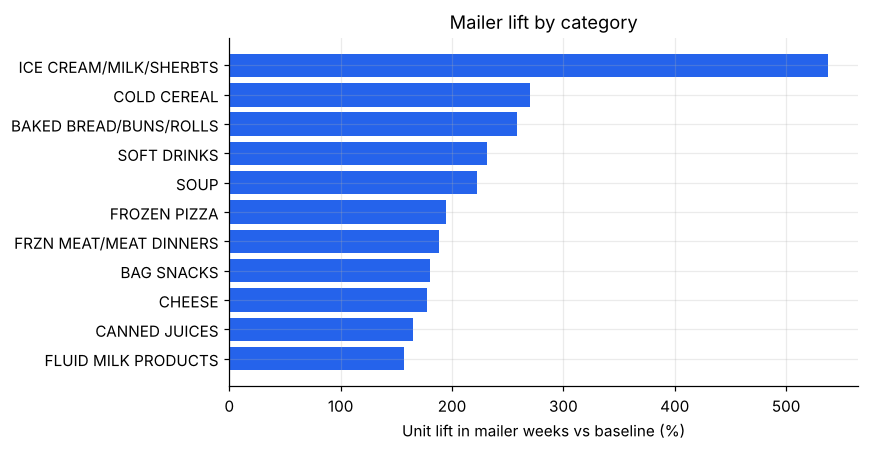

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(by_cat.index[::-1], by_cat.lift[::-1] * 100, color=BLUE)
ax.set_xlabel("Unit lift in mailer weeks vs baseline (%)"); ax.set_title("Mailer lift by category")
fig.tight_layout(); fig.savefig(CH / "01_lift_by_category.png", bbox_inches="tight")

## 3. Cannibalization: what happens to sister items?
For each category-week, compare units of **non-promoted** items when at least one sister item is on the mailer
vs. weeks with no mailer activity in that category (same items, item-level fixed effects).

In [5]:
full["cat_mailer_items"] = full.groupby(["product_category", "week"]).on_mailer.transform("sum")
sis = full[~full.on_mailer & ~full.on_display].copy()
sis["sister_on_mailer"] = (sis.cat_mailer_items > 0).astype(int)
m_can = smf.ols("np.log1p(units) ~ sister_on_mailer + C(product_id) + C(week % 13)", data=sis).fit()
can = np.expm1(m_can.params["sister_on_mailer"])
print(f"Non-promoted items sell {can:+.1%} units in weeks when a sister item is on the mailer "
      f"(p = {m_can.pvalues['sister_on_mailer']:.3f})")

Non-promoted items sell -0.6% units in weeks when a sister item is on the mailer (p = 0.506)


## 4. Price elasticity by category
log(units) = β·log(paid price) + mailer + display + item fixed effects + week fixed effects.

In [6]:
rows = []
for cat, g in panel.groupby("product_category"):
    g = g[g.paid_price > 0]
    m = smf.ols("np.log(units) ~ np.log(paid_price) + on_mailer + on_display + C(product_id) + C(week)", data=g).fit()
    rows.append({"category": cat, "elasticity": m.params["np.log(paid_price)"],
                 "se": m.bse["np.log(paid_price)"], "mailer_effect": np.expm1(m.params["on_mailer[T.True]"]),
                 "n": len(g)})
el = pd.DataFrame(rows).sort_values("elasticity")
el.round(2)

,category,elasticity,se,mailer_effect,n
10,SOFT DRINKS,-1.82,0.05,0.45,10779
5,COLD CEREAL,-1.79,0.07,0.41,6319
7,FROZEN PIZZA,-1.63,0.07,0.33,5884
2,BEERS/ALES,-1.51,0.30,0.05,2252
0,BAG SNACKS,-1.46,0.07,0.24,7105
11,SOUP,-1.31,0.07,0.58,6274
6,FLUID MILK PRODUCTS,-1.17,0.09,0.74,3282
8,FRZN MEAT/MEAT DINNERS,-1.13,0.06,0.28,9499
3,CANNED JUICES,-1.10,0.09,0.49,4685
9,ICE CREAM/MILK/SHERBTS,-1.06,0.06,0.65,3147


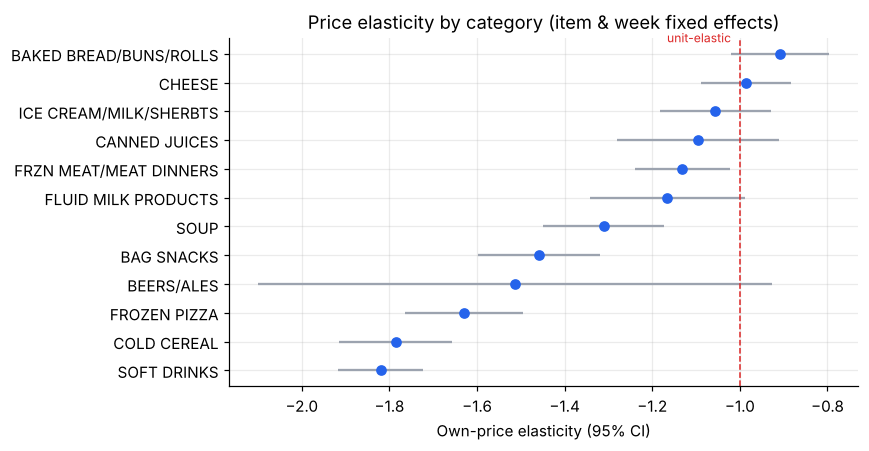

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.errorbar(el.elasticity, range(len(el)), xerr=1.96 * el.se, fmt="o", color=BLUE, ecolor=GREY)
ax.axvline(-1, color=RED, ls="--", lw=1); ax.text(-1.02, len(el) - .6, "unit-elastic", color=RED, ha="right", fontsize=8)
ax.set_yticks(range(len(el))); ax.set_yticklabels(el.category); ax.set_xlabel("Own-price elasticity (95% CI)")
ax.set_title("Price elasticity by category (item & week fixed effects)")
fig.tight_layout(); fig.savefig(CH / "02_elasticity.png", bbox_inches="tight")

## 5. Keep / change / drop scorecard
Retailer cost is not in the data, so a **30% gross margin on shelf price** is assumed (typical center-store).
For a discount of depth *d* and margin *m*, the promo only pays for itself (without vendor funding) when
unit lift ≥ **d / (m − d)**. If *d ≥ m* every promo unit is sold below cost, so the event only works
with vendor/trade funding or a shallower discount.

In [8]:
GM = 0.30
ev["depth"] = 1 - ev.paid_price / ev.shelf_price
score = (ev.groupby("product_category")
           .agg(events=("depth", "size"), median_lift=("lift_pct", "median"), discount_depth=("depth", "mean"))
           .join(el.set_index("category")[["elasticity"]]))
score["breakeven_lift"] = np.where(score.discount_depth < GM, score.discount_depth / (GM - score.discount_depth), np.inf)
score["decision"] = np.select(
    [score.discount_depth >= GM, score.median_lift >= score.breakeven_lift],
    ["CHANGE: needs vendor funding or shallower discount", "KEEP: lift covers the discount"],
    "DROP / rethink: lift below break-even")
score = score.sort_values("discount_depth")
print(score.decision.value_counts().to_string())
score.round(2)

decision
CHANGE: needs vendor funding or shallower discount    6
DROP / rethink: lift below break-even                 4
KEEP: lift covers the discount                        1


,events,median_lift,discount_depth,elasticity,breakeven_lift,decision
product_category,,,,,,
CANNED JUICES,88,1.42,0.15,-1.10,1.05,KEEP: lift covers the discount
BAG SNACKS,38,1.00,0.23,-1.46,3.10,DROP / rethink: lift below break-even
FROZEN PIZZA,109,1.00,0.25,-1.63,5.44,DROP / rethink: lift below break-even
SOUP,146,2.00,0.27,-1.31,8.26,DROP / rethink: lift below break-even
COLD CEREAL,376,2.00,0.29,-1.79,58.15,DROP / rethink: lift below break-even
FRZN MEAT/MEAT DINNERS,575,2.00,0.33,-1.13,inf,CHANGE: needs vendor funding or shallower disc...
BAKED BREAD/BUNS/ROLLS,45,1.00,0.35,-0.91,inf,CHANGE: needs vendor funding or shallower disc...
SOFT DRINKS,460,1.67,0.35,-1.82,inf,CHANGE: needs vendor funding or shallower disc...
FLUID MILK PRODUCTS,87,1.50,0.35,-1.17,inf,CHANGE: needs vendor funding or shallower disc...


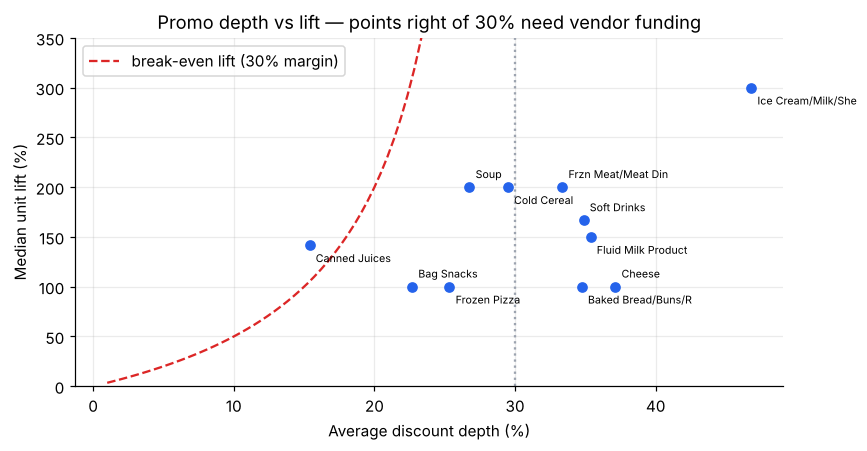

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ok = score[np.isfinite(score.breakeven_lift)]
ax.scatter(score.discount_depth * 100, score.median_lift * 100, color=BLUE, zorder=3)
for i, (c, r) in enumerate(score.iterrows()):
    ax.annotate(c.title()[:18], (r.discount_depth * 100, r.median_lift * 100), fontsize=7,
                xytext=(4, 6 if i % 2 else -11), textcoords="offset points")
dd = np.linspace(1, 29, 60); ax.plot(dd, dd / (30 - dd) * 100, color=RED, ls="--", label="break-even lift (30% margin)")
ax.axvline(30, color=GREY, ls=":"); ax.set_ylim(0, max(350, score.median_lift.max() * 110))
ax.set_xlabel("Average discount depth (%)"); ax.set_ylabel("Median unit lift (%)"); ax.legend(loc="upper left")
ax.set_title("Promo depth vs lift — points right of 30% need vendor funding")
fig.tight_layout(); fig.savefig(CH / "04_depth_vs_lift.png", bbox_inches="tight")

## 6. Price-architecture audit

Median private-label discount vs national brand: 27%; 11 of 93 product types have private label priced ABOVE national brand
Share of items by last price digit (cents): {0: 6.0, 1: 0.5, 2: 0.9, 3: 1.7, 4: 2.1, 5: 4.5, 6: 0.8, 7: 0.9, 8: 2.6, 9: 80.0}


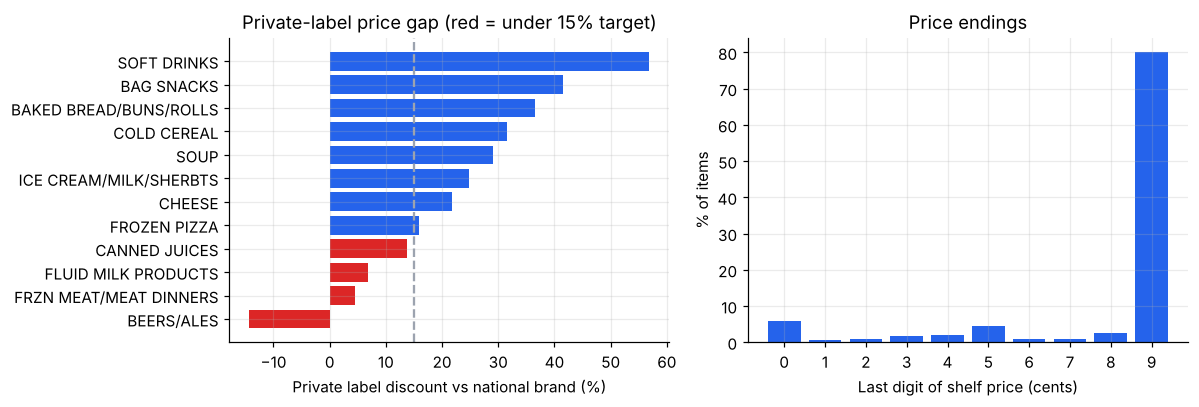

In [10]:
price = con.execute("""
select p.product_category, p.product_type, p.brand, p.product_id,
       median((t.sales_value + t.retail_disc) / t.quantity) as shelf_price
from transactions t join products p using (product_id)
where p.product_category in (select product_category from cats) and t.quantity between 1 and 50
group by all
""").df()
gap = (price.groupby(["product_category", "product_type", "brand"]).shelf_price.median().unstack()
            .dropna().assign(pl_gap=lambda x: 1 - x.Private / x.National))
gap_cat = gap.groupby(level=0).pl_gap.median().sort_values()
inverted = (gap.pl_gap < 0).sum()
endings = (np.round(price.shelf_price * 100) % 10).astype(int).value_counts(normalize=True).sort_index()
print(f"Median private-label discount vs national brand: {gap.pl_gap.median():.0%}; "
      f"{inverted} of {len(gap)} product types have private label priced ABOVE national brand")
print("Share of items by last price digit (cents):", (endings * 100).round(1).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].barh(gap_cat.index, gap_cat.values * 100, color=[RED if v < .15 else BLUE for v in gap_cat.values])
ax[0].axvline(15, color=GREY, ls="--"); ax[0].set_xlabel("Private label discount vs national brand (%)")
ax[0].set_title("Private-label price gap (red = under 15% target)")
ax[1].bar(endings.index.astype(str), endings.values * 100, color=BLUE); ax[1].set_xlabel("Last digit of shelf price (cents)")
ax[1].set_title("Price endings"); ax[1].set_ylabel("% of items")
fig.tight_layout(); fig.savefig(CH / "03_price_audit.png", bbox_inches="tight")

## Findings & recommendations
The printed numbers above feed the README summary. In short:
* Mailer weeks lift units strongly, but part of the lift is pulled forward from the following week and
  sister items lose some volume — **gross lift overstates true incremental volume**.
* Elasticities differ a lot by category; deep discounts in inelastic categories give away margin on baseline units.
* The scorecard flags which categories to KEEP, run with a **shallower discount**, or DROP.
* Price audit: product types where private label is priced too close to (or above) the national brand weaken the
  value ladder; fix these first.

*Limitations:* 801-household sample (not full store sales), so item-week volumes are small and noisy;
product cost is assumed (30% margin); mailer/display flags are chain-level aggregates of store records.